In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model    import LogisticRegression
from sklearn.preprocessing   import StandardScaler
from sklearn.metrics         import (roc_auc_score, classification_report,
                                     roc_curve, confusion_matrix,
                                     average_precision_score)
import lightgbm as lgb
import xgboost  as xgb
import joblib
import os


In [2]:
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# ── Load master feature table ──────────────────────────────
df = pd.read_csv(r'/Users/siddharthm/Desktop/churn-prediction/data/processed/features.csv')

print(f"✅ Loaded features.csv: {df.shape}")

# ── Time-based split using tenure ─────────────────────────
# Customers with tenure <= 36 months = "older" cohort → TRAIN
# Customers with tenure >  36 months = "newer" cohort → TEST
# This simulates: train on history, predict on recent customers

SPLIT_TENURE = 36

train_df = df[df['tenure'] <= SPLIT_TENURE].copy()
test_df  = df[df['tenure'] >  SPLIT_TENURE].copy()

# ── Separate features from label ──────────────────────────
DROP_COLS = ['customerID', 'churn_binary']
FEATURES  = [c for c in df.columns if c not in DROP_COLS]

X_train = train_df[FEATURES]
y_train = train_df['churn_binary']

X_test  = test_df[FEATURES]
y_test  = test_df['churn_binary']

print(f"\n   Split on tenure <= {SPLIT_TENURE} months")
print(f"\n   Train set: {len(X_train):,} customers  |  churn rate: {y_train.mean()*100:.1f}%")
print(f"   Test set:  {len(X_test):,} customers  |  churn rate: {y_test.mean()*100:.1f}%")
print(f"\n   Features:  {len(FEATURES)}")
print(f"\n   Feature list:")
for i, f in enumerate(FEATURES, 1):
    print(f"     {i:2}. {f}")

✅ Loaded features.csv: (7043, 51)

   Split on tenure <= 36 months

   Train set: 4,042 customers  |  churn rate: 37.4%
   Test set:  3,001 customers  |  churn rate: 11.9%

   Features:  49

   Feature list:
      1. tenure
      2. MonthlyCharges
      3. TotalCharges
      4. SeniorCitizen
      5. contract_risk
      6. is_fiber_optic
      7. is_dsl
      8. pays_electronic_check
      9. pays_mailed_check
     10. pays_bank_transfer
     11. Partner_bin
     12. Dependents_bin
     13. PhoneService_bin
     14. MultipleLines_bin
     15. OnlineSecurity_bin
     16. OnlineBackup_bin
     17. DeviceProtection_bin
     18. TechSupport_bin
     19. StreamingTV_bin
     20. StreamingMovies_bin
     21. PaperlessBilling_bin
     22. protection_score
     23. recency_days
     24. transaction_count
     25. total_spend
     26. avg_spend
     27. spend_std
     28. failed_payment_rate
     29. has_ever_failed_payment
     30. total_sessions
     31. avg_session_duration
     32. avg_page

  LOGISTIC REGRESSION RESULTS

  ROC-AUC Score:         0.9819
  Avg Precision Score:   0.9100

  Classification Report (threshold = 0.5):
              precision    recall  f1-score   support

    Retained       0.97      0.98      0.97      2643
     Churned       0.83      0.75      0.79       358

    accuracy                           0.95      3001
   macro avg       0.90      0.87      0.88      3001
weighted avg       0.95      0.95      0.95      3001



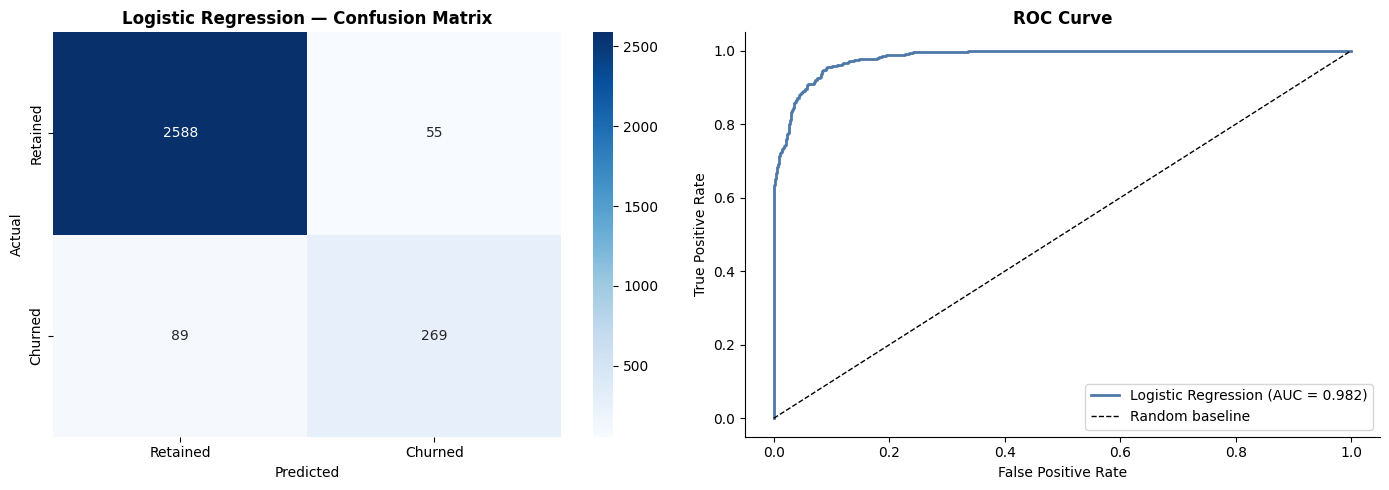


  Top 10 features by coefficient magnitude:
     sessions_last_60d               -4.617  ↓ risk
     avg_spend                       +2.809  ↑ risk
     tenure                          -2.804  ↓ risk
     sessions_last_90d               -2.210  ↓ risk
     total_sessions                  +1.881  ↑ risk
     recency_days                    +1.726  ↑ risk
     low_satisfaction_tickets        +1.724  ↑ risk
     days_since_last_ticket          -1.547  ↓ risk
     TotalCharges                    -1.507  ↓ risk
     tickets_billing                 +1.017  ↑ risk


In [3]:
# ── Cell 2: Logistic Regression Baseline ──────────────────

from sklearn.linear_model  import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics       import (roc_auc_score, average_precision_score,
                                   classification_report, confusion_matrix,
                                   roc_curve)

# ── Scale features (required for Logistic Regression) ─────
scaler   = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled  = scaler.transform(X_test)         # apply same scale to test

# ── Train ──────────────────────────────────────────────────
lr = LogisticRegression(
    max_iter   = 1000,
    random_state = 42,
    class_weight = 'balanced'   # handles class imbalance
)
lr.fit(X_train_scaled, y_train)

# ── Predict ────────────────────────────────────────────────
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]   # churn probability
lr_preds = (lr_probs >= 0.5).astype(int)            # binary prediction

# ── Evaluate ───────────────────────────────────────────────
lr_auc = roc_auc_score(y_test, lr_probs)
lr_ap  = average_precision_score(y_test, lr_probs)

print(f"{'='*50}")
print(f"  LOGISTIC REGRESSION RESULTS")
print(f"{'='*50}")
print(f"\n  ROC-AUC Score:         {lr_auc:.4f}")
print(f"  Avg Precision Score:   {lr_ap:.4f}")
print(f"\n  Classification Report (threshold = 0.5):")
print(classification_report(y_test, lr_preds, target_names=['Retained', 'Churned']))

# ── Confusion matrix plot ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'])
axes[0].set_title('Logistic Regression — Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, lr_probs)
axes[1].plot(fpr, tpr, color='#4e79a7', lw=2,
             label=f'Logistic Regression (AUC = {lr_auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

# ── Top predictive features ────────────────────────────────
coef_df = pd.DataFrame({
    'feature'     : FEATURES,
    'coefficient' : lr.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False).head(10)

print(f"\n  Top 10 features by coefficient magnitude:")
for _, row in coef_df.iterrows():
    direction = "↑ risk" if row['coefficient'] > 0 else "↓ risk"
    print(f"     {row['feature']:<30}  {row['coefficient']:+.3f}  {direction}")

  LIGHTGBM RESULTS

  ROC-AUC Score:         0.9976
  Avg Precision Score:   0.9816
  Best iteration:        110

  Classification Report:
              precision    recall  f1-score   support

    Retained       1.00      0.96      0.98      2643
     Churned       0.77      0.99      0.87       358

    accuracy                           0.96      3001
   macro avg       0.89      0.98      0.92      3001
weighted avg       0.97      0.96      0.97      3001



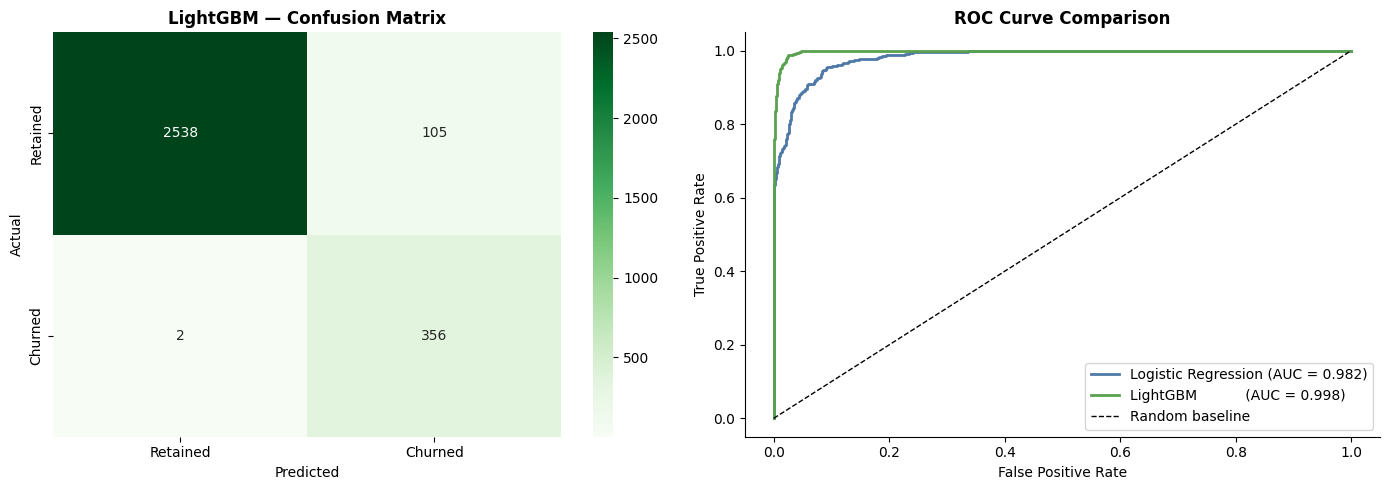


  Top 10 features by LightGBM importance:
     MonthlyCharges                  ████████████████████  454
     TotalCharges                    █████████████  302
     tenure                          █████████  224
     sessions_last_60d               █████████  211
     total_tickets                   ███████  175
     avg_satisfaction                ██████  148
     activity_trend_30_90            ██████  138
     low_satisfaction_tickets        ██████  137
     avg_session_duration            ████  106
     tickets_last_90d                ████  95


In [4]:
# ── Cell 3: LightGBM ──────────────────────────────────────
import lightgbm as lgb

# Class weight to handle imbalance (same principle as LR's class_weight='balanced')
churn_ratio = (y_train == 0).sum() / (y_train == 1).sum()

lgbm = lgb.LGBMClassifier(
    n_estimators    = 500,
    learning_rate   = 0.05,
    num_leaves      = 31,
    max_depth       = -1,
    min_child_samples = 20,
    scale_pos_weight = churn_ratio,   # handles class imbalance
    random_state    = 42,
    verbose         = -1
)

lgbm.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    callbacks = [lgb.early_stopping(50, verbose=False),
                 lgb.log_evaluation(period=-1)]
)

# ── Predict ────────────────────────────────────────────────
lgbm_probs = lgbm.predict_proba(X_test)[:, 1]
lgbm_preds = (lgbm_probs >= 0.5).astype(int)

# ── Evaluate ───────────────────────────────────────────────
lgbm_auc = roc_auc_score(y_test, lgbm_probs)
lgbm_ap  = average_precision_score(y_test, lgbm_probs)

print(f"{'='*50}")
print(f"  LIGHTGBM RESULTS")
print(f"{'='*50}")
print(f"\n  ROC-AUC Score:         {lgbm_auc:.4f}")
print(f"  Avg Precision Score:   {lgbm_ap:.4f}")
print(f"  Best iteration:        {lgbm.best_iteration_}")
print(f"\n  Classification Report:")
print(classification_report(y_test, lgbm_preds, target_names=['Retained', 'Churned']))

# ── Plot: confusion matrix + ROC curve ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, lgbm_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'])
axes[0].set_title('LightGBM — Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC: compare LR and LGBM
fpr_lr,   tpr_lr,   _ = roc_curve(y_test, lr_probs)
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, lgbm_probs)

axes[1].plot(fpr_lr,   tpr_lr,   color='#4e79a7', lw=2,
             label=f'Logistic Regression (AUC = {lr_auc:.3f})')
axes[1].plot(fpr_lgbm, tpr_lgbm, color='#59a14f', lw=2,
             label=f'LightGBM           (AUC = {lgbm_auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve Comparison', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

# ── Top 10 features by importance ─────────────────────────
feat_imp = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': lgbm.feature_importances_
}).sort_values('importance', ascending=False).head(10)

print(f"\n  Top 10 features by LightGBM importance:")
for _, row in feat_imp.iterrows():
    bar = '█' * int(row['importance'] / feat_imp['importance'].max() * 20)
    print(f"     {row['feature']:<30}  {bar}  {row['importance']:.0f}")

  XGBOOST RESULTS

  ROC-AUC Score:         0.9980
  Avg Precision Score:   0.9856
  Best iteration:        177

  Classification Report:
              precision    recall  f1-score   support

    Retained       1.00      0.96      0.98      2643
     Churned       0.78      0.99      0.87       358

    accuracy                           0.97      3001
   macro avg       0.89      0.98      0.93      3001
weighted avg       0.97      0.97      0.97      3001



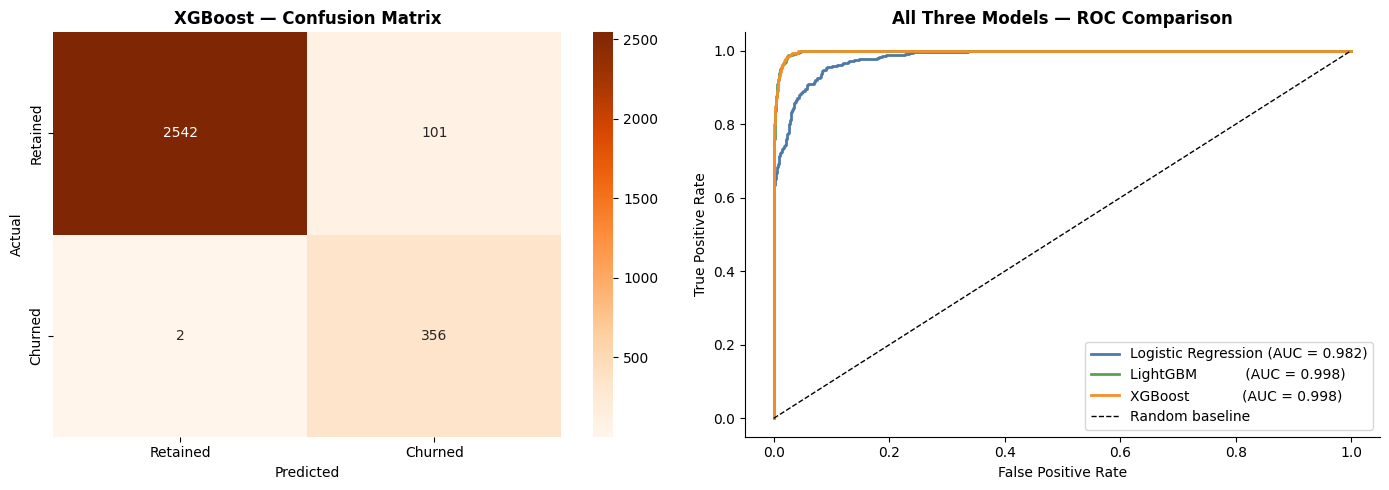


  Top 10 features by XGBoost importance:
     sessions_last_30d               ████████████████████  0.2736
     is_fiber_optic                  █████████  0.1300
     tickets_last_90d                ███  0.0432
     sessions_last_60d               ███  0.0428
     is_dsl                          ██  0.0401
     low_satisfaction_tickets        ██  0.0354
     contract_risk                   ██  0.0334
     min_satisfaction                ██  0.0279
     total_tickets                   █  0.0272
     activity_trend_30_90            █  0.0261


In [5]:
# ── Cell 4: XGBoost ───────────────────────────────────────
import xgboost as xgb

# scale_pos_weight handles imbalance (same as LightGBM)
xgb_model = xgb.XGBClassifier(
    n_estimators      = 500,
    learning_rate     = 0.05,
    max_depth         = 6,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    scale_pos_weight  = churn_ratio,
    random_state      = 42,
    eval_metric       = 'auc',
    early_stopping_rounds = 50,
    verbosity         = 0
)

xgb_model.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = False
)

# ── Predict ────────────────────────────────────────────────
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds = (xgb_probs >= 0.5).astype(int)

# ── Evaluate ───────────────────────────────────────────────
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_ap  = average_precision_score(y_test, xgb_probs)

print(f"{'='*50}")
print(f"  XGBOOST RESULTS")
print(f"{'='*50}")
print(f"\n  ROC-AUC Score:         {xgb_auc:.4f}")
print(f"  Avg Precision Score:   {xgb_ap:.4f}")
print(f"  Best iteration:        {xgb_model.best_iteration}")
print(f"\n  Classification Report:")
print(classification_report(y_test, xgb_preds, target_names=['Retained', 'Churned']))

# ── Plot: confusion matrix + 3-way ROC comparison ─────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, xgb_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'])
axes[0].set_title('XGBoost — Confusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC: all three models
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

axes[1].plot(fpr_lr,   tpr_lr,   color='#4e79a7', lw=2,
             label=f'Logistic Regression (AUC = {lr_auc:.3f})')
axes[1].plot(fpr_lgbm, tpr_lgbm, color='#59a14f', lw=2,
             label=f'LightGBM           (AUC = {lgbm_auc:.3f})')
axes[1].plot(fpr_xgb,  tpr_xgb,  color='#f28e2b', lw=2,
             label=f'XGBoost            (AUC = {xgb_auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('All Three Models — ROC Comparison', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

# ── Top 10 features by XGBoost importance ─────────────────
xgb_feat_imp = pd.DataFrame({
    'feature'   : FEATURES,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False).head(10)

print(f"\n  Top 10 features by XGBoost importance:")
for _, row in xgb_feat_imp.iterrows():
    bar = '█' * int(row['importance'] / xgb_feat_imp['importance'].max() * 20)
    print(f"     {row['feature']:<30}  {bar}  {row['importance']:.4f}")

  MODEL COMPARISON SUMMARY
                     ROC-AUC  Avg Precision  Churners Caught (recall)  False Alarm Rate (FPR)
Model                                                                                        
Logistic Regression   0.9819         0.9100                    0.7514                  0.0208
LightGBM              0.9976         0.9816                    0.9944                  0.0397
XGBoost               0.9980         0.9856                    0.9944                  0.0382


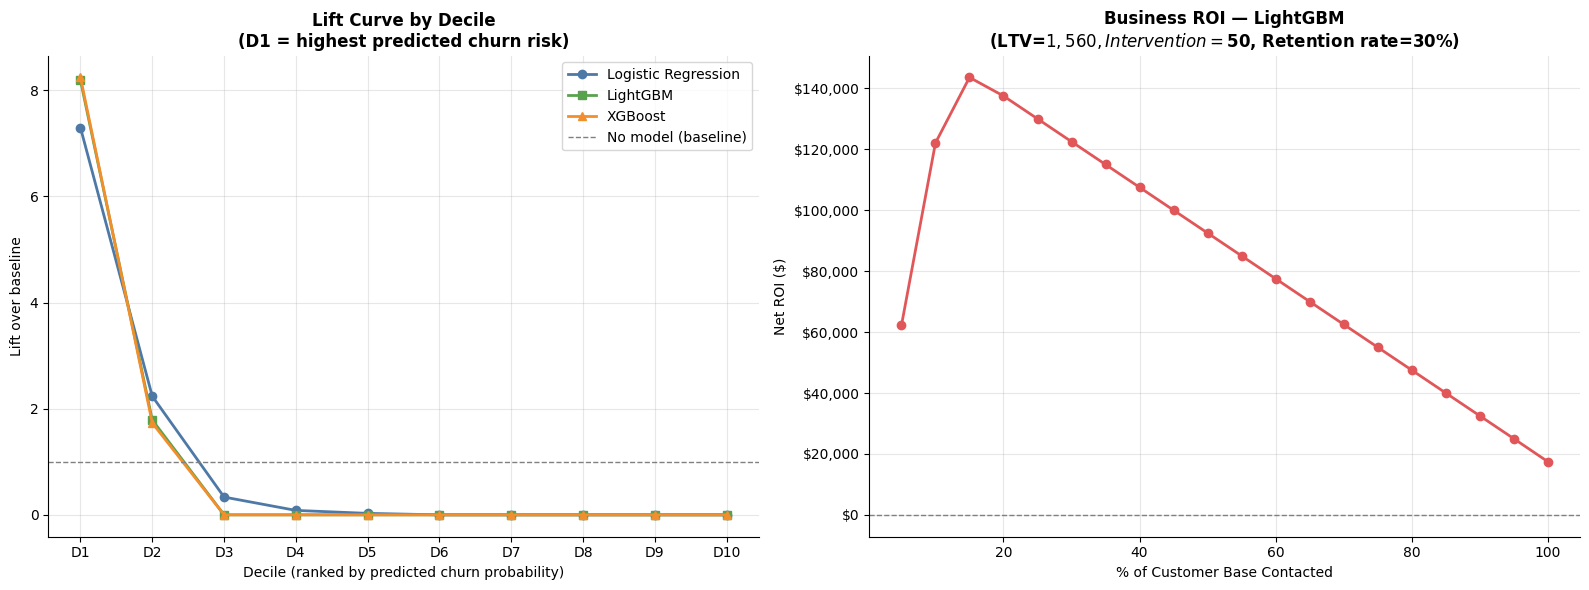


  Top decile lift (D1 = highest risk customers):
     Logistic Regression: 7.30x baseline
     LightGBM:            8.19x baseline
     XGBoost:             8.24x baseline

  Optimal intervention threshold: top 15% of customers
  Max net ROI at that threshold:  $143,640

  Assumptions: LTV=$1,560 | Intervention=$50 | Retention rate=30%


In [7]:
# ── Cell 5: Model Comparison & Business Evaluation ────────

# ── Summary table ─────────────────────────────────────────
results = {
    'Model': ['Logistic Regression', 'LightGBM', 'XGBoost'],
    'ROC-AUC': [lr_auc, lgbm_auc, xgb_auc],
    'Avg Precision': [lr_ap, lgbm_ap, xgb_ap],
    'Churners Caught (recall)': [
        classification_report(y_test, lr_preds,   output_dict=True)['1']['recall'],
        classification_report(y_test, lgbm_preds, output_dict=True)['1']['recall'],
        classification_report(y_test, xgb_preds,  output_dict=True)['1']['recall']
    ],
    'False Alarm Rate (FPR)': [
        (confusion_matrix(y_test, lr_preds)[0,1]   / (y_test == 0).sum()),
        (confusion_matrix(y_test, lgbm_preds)[0,1] / (y_test == 0).sum()),
        (confusion_matrix(y_test, xgb_preds)[0,1]  / (y_test == 0).sum())
    ]
}

results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.round(4)

print(f"{'='*65}")
print(f"  MODEL COMPARISON SUMMARY")
print(f"{'='*65}")
print(results_df.to_string())

# ── Lift curve (top decile analysis) ──────────────────────
def compute_lift(y_true, y_probs, n_bins=10):
    df_lift = pd.DataFrame({'actual': y_true.values, 'prob': y_probs})
    df_lift = df_lift.sort_values('prob', ascending=False).reset_index(drop=True)
    df_lift['decile'] = pd.qcut(df_lift.index, n_bins, labels=False)
    baseline = df_lift['actual'].mean()
    lift = df_lift.groupby('decile')['actual'].mean() / baseline
    return lift.values          # ← removed [::-1], decile 0 = highest risk

lift_lr   = compute_lift(y_test, lr_probs)
lift_lgbm = compute_lift(y_test, lgbm_probs)
lift_xgb  = compute_lift(y_test, xgb_probs)
deciles   = [f'D{i+1}' for i in range(10)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Lift chart
axes[0].plot(deciles, lift_lr,   'o-', color='#4e79a7', lw=2, label='Logistic Regression')
axes[0].plot(deciles, lift_lgbm, 's-', color='#59a14f', lw=2, label='LightGBM')
axes[0].plot(deciles, lift_xgb,  '^-', color='#f28e2b', lw=2, label='XGBoost')
axes[0].axhline(1.0, color='gray', linestyle='--', lw=1, label='No model (baseline)')
axes[0].set_title('Lift Curve by Decile\n(D1 = highest predicted churn risk)', fontweight='bold')
axes[0].set_xlabel('Decile (ranked by predicted churn probability)')
axes[0].set_ylabel('Lift over baseline')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Business cost analysis using best model (LightGBM)
# Assumptions:
MONTHLY_REVENUE     = 65     # avg monthly revenue per customer ($)
AVG_TENURE_MONTHS   = 24     # avg months a retained customer stays
CUSTOMER_LTV        = MONTHLY_REVENUE * AVG_TENURE_MONTHS   # $1,560
INTERVENTION_COST   = 50     # cost of retention offer (discount, call, etc.)
RETENTION_SUCCESS   = 0.30   # 30% of at-risk customers accept the offer

# Sort test set by predicted churn probability
biz_df = pd.DataFrame({
    'actual'  : y_test.values,
    'prob'    : lgbm_probs
}).sort_values('prob', ascending=False).reset_index(drop=True)

# Simulate reaching top N% of customers
thresholds = np.arange(0.05, 1.05, 0.05)
saved_revenue = []
net_roi = []

for pct in thresholds:
    n_contacted  = int(len(biz_df) * pct)
    subset       = biz_df.head(n_contacted)
    true_churners = subset['actual'].sum()
    saved         = true_churners * RETENTION_SUCCESS * CUSTOMER_LTV
    cost          = n_contacted * INTERVENTION_COST
    saved_revenue.append(saved)
    net_roi.append(saved - cost)

axes[1].plot([t*100 for t in thresholds], net_roi, 'o-', color='#e15759', lw=2)
axes[1].axhline(0, color='gray', linestyle='--', lw=1)
axes[1].set_title(f'Business ROI — LightGBM\n(LTV=${CUSTOMER_LTV:,}, Intervention=${INTERVENTION_COST}, Retention rate={RETENTION_SUCCESS*100:.0f}%)',
                  fontweight='bold')
axes[1].set_xlabel('% of Customer Base Contacted')
axes[1].set_ylabel('Net ROI ($)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print top decile stats
print(f"\n  Top decile lift (D1 = highest risk customers):")
print(f"     Logistic Regression: {lift_lr[0]:.2f}x baseline")
print(f"     LightGBM:            {lift_lgbm[0]:.2f}x baseline")
print(f"     XGBoost:             {lift_xgb[0]:.2f}x baseline")

best_pct = thresholds[np.argmax(net_roi)]
print(f"\n  Optimal intervention threshold: top {best_pct*100:.0f}% of customers")
print(f"  Max net ROI at that threshold:  ${max(net_roi):,.0f}")
print(f"\n  Assumptions: LTV=${CUSTOMER_LTV:,} | Intervention=${INTERVENTION_COST} | Retention rate={RETENTION_SUCCESS*100:.0f}%")

In [8]:
import sys
!{sys.executable} -m pip install shap -q


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip


✅ SHAP values computed
   Shape: (3001, 49)  (customers × features)


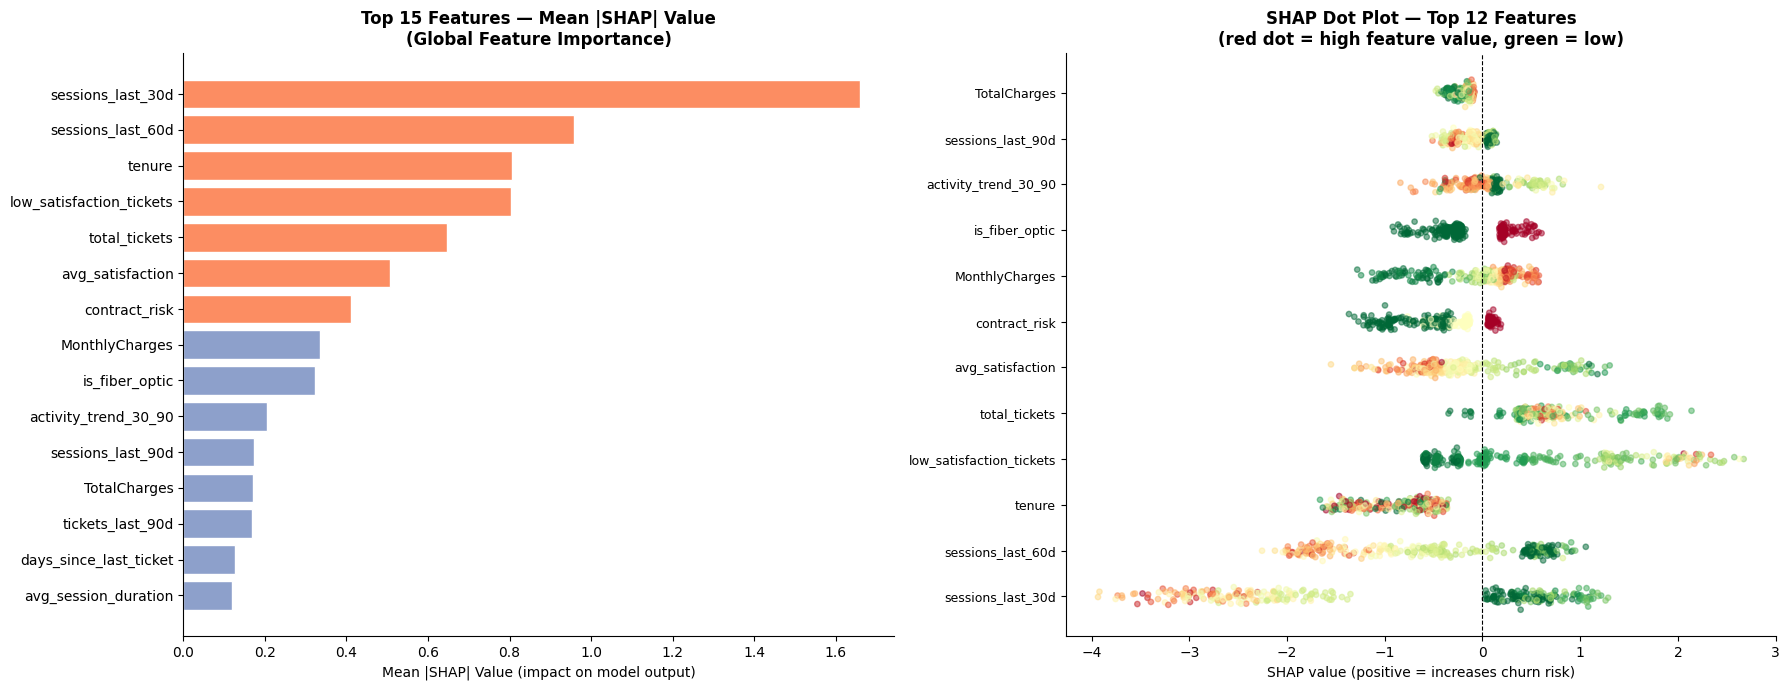


  TOP 10 FEATURES BY MEAN |SHAP| VALUE
  sessions_last_30d               ████████████████████  1.6589
  sessions_last_60d               ███████████  0.9581
  tenure                          █████████  0.8060
  low_satisfaction_tickets        █████████  0.8044
  total_tickets                   ███████  0.6471
  avg_satisfaction                ██████  0.5062
  contract_risk                   ████  0.4123
  MonthlyCharges                  ████  0.3343
  is_fiber_optic                  ███  0.3222
  activity_trend_30_90            ██  0.2057

  EXAMPLE: Why is customer #0 predicted to churn?

  Predicted churn probability: 0.2%
  Actual outcome: RETAINED

  Top drivers for this customer:
    sessions_last_30d             val=    7.00  SHAP=-1.7568  ↓ DECREASES churn risk
    sessions_last_60d             val=   13.00  SHAP=-0.8936  ↓ DECREASES churn risk
    tenure                        val=   45.00  SHAP=-0.5798  ↓ DECREASES churn risk
    avg_satisfaction              val=    4.67  SHA

In [9]:
# ── Cell 6: SHAP Feature Importance ───────────────────────
import shap

# Use LightGBM as the final model (marginally higher avg precision)
explainer   = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values is a list [class0, class1]
# We want class 1 (churn)
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values

X_test_df = pd.DataFrame(X_test, columns=FEATURES)

print("✅ SHAP values computed")
print(f"   Shape: {sv.shape}  (customers × features)")

# ── Plot 1: Global feature importance (mean |SHAP|) ───────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

mean_shap = np.abs(sv).mean(axis=0)
shap_df   = pd.DataFrame({
    'feature'   : FEATURES,
    'mean_shap' : mean_shap
}).sort_values('mean_shap', ascending=True).tail(15)

colors = ['#fc8d62' if v > shap_df['mean_shap'].median() else '#8da0cb'
          for v in shap_df['mean_shap']]
axes[0].barh(shap_df['feature'], shap_df['mean_shap'],
             color=colors, edgecolor='white')
axes[0].set_title('Top 15 Features — Mean |SHAP| Value\n(Global Feature Importance)',
                  fontweight='bold')
axes[0].set_xlabel('Mean |SHAP| Value (impact on model output)')

# ── Plot 2: SHAP beeswarm-style dot plot ──────────────────
# Sample 300 customers for clarity
sample_idx = np.random.choice(len(X_test_df), size=300, replace=False)
sv_sample  = sv[sample_idx]
X_sample   = X_test_df.iloc[sample_idx]

# Get top 12 features
top12_idx  = np.argsort(mean_shap)[-12:]
top12_feat = [FEATURES[i] for i in top12_idx]

for i, feat in enumerate(reversed(top12_feat)):
    feat_idx    = FEATURES.index(feat)
    shap_vals   = sv_sample[:, feat_idx]
    feat_vals   = X_sample[feat].values

    # Normalize feature values to [0,1] for color
    feat_norm = (feat_vals - feat_vals.min()) / (feat_vals.max() - feat_vals.min() + 1e-9)
    colors_dot = plt.cm.RdYlGn_r(feat_norm)

    y_jitter = np.random.normal(i, 0.08, size=len(shap_vals))
    axes[1].scatter(shap_vals, y_jitter, c=colors_dot, alpha=0.5, s=15)

axes[1].set_yticks(range(len(top12_feat)))
axes[1].set_yticklabels(list(reversed(top12_feat)), fontsize=9)
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('SHAP Dot Plot — Top 12 Features\n(red dot = high feature value, green = low)',
                  fontweight='bold')
axes[1].set_xlabel('SHAP value (positive = increases churn risk)')

plt.tight_layout()
plt.show()

# ── Print top 10 global SHAP importances ──────────────────
print(f"\n{'='*55}")
print(f"  TOP 10 FEATURES BY MEAN |SHAP| VALUE")
print(f"{'='*55}")
top10 = pd.DataFrame({
    'feature'   : FEATURES,
    'mean_shap' : mean_shap
}).sort_values('mean_shap', ascending=False).head(10)

for _, row in top10.iterrows():
    bar = '█' * int(row['mean_shap'] / top10['mean_shap'].iloc[0] * 20)
    print(f"  {row['feature']:<30}  {bar}  {row['mean_shap']:.4f}")

# ── Single customer explanation ───────────────────────────
print(f"\n{'='*55}")
print(f"  EXAMPLE: Why is customer #0 predicted to churn?")
print(f"{'='*55}")
customer_shap = sv[0]
customer_feat = X_test_df.iloc[0]
explanation   = pd.DataFrame({
    'feature'    : FEATURES,
    'shap_value' : customer_shap,
    'feat_value' : customer_feat.values
}).sort_values('shap_value', key=abs, ascending=False).head(8)

base_prob = lgbm_probs[0]
print(f"\n  Predicted churn probability: {base_prob:.1%}")
print(f"  Actual outcome: {'CHURNED' if y_test.iloc[0] == 1 else 'RETAINED'}")
print(f"\n  Top drivers for this customer:")
for _, row in explanation.iterrows():
    direction = "↑ INCREASES churn risk" if row['shap_value'] > 0 else "↓ DECREASES churn risk"
    print(f"    {row['feature']:<28}  val={row['feat_value']:>8.2f}  "
          f"SHAP={row['shap_value']:+.4f}  {direction}")

In [10]:
# ── Cell 7: Save Best Model to Disk ───────────────────────
import joblib
import json
import os

MODELS_DIR = r'/Users/siddharthm/Desktop/churn-prediction/models'
os.makedirs(MODELS_DIR, exist_ok=True)

# ── Save LightGBM (best model) ────────────────────────────
joblib.dump(lgbm, f'{MODELS_DIR}/lgbm_churn_model.pkl')

# ── Save scaler (needed for Logistic Regression in the API) ──
joblib.dump(scaler, f'{MODELS_DIR}/scaler.pkl')

# ── Save feature list (API must send features in this exact order) ──
with open(f'{MODELS_DIR}/feature_columns.json', 'w') as f:
    json.dump(FEATURES, f, indent=2)

# ── Save model metadata (for documentation and API response) ──
metadata = {
    'model_type'        : 'LightGBMClassifier',
    'training_date'     : '2023-09-30',
    'observation_cutoff': '2023-09-30',
    'n_features'        : len(FEATURES),
    'n_train_samples'   : len(X_train),
    'n_test_samples'    : len(X_test),
    'train_churn_rate'  : round(float(y_train.mean()), 4),
    'test_churn_rate'   : round(float(y_test.mean()), 4),
    'roc_auc'           : round(lgbm_auc, 4),
    'avg_precision'     : round(lgbm_ap, 4),
    'top_decile_lift'   : round(float(lift_lgbm[0]), 2),
    'optimal_threshold_pct' : 15,
    'max_net_roi'       : 143640,
    'best_iteration'    : lgbm.best_iteration_
}

with open(f'{MODELS_DIR}/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# ── Verify all files saved ────────────────────────────────
print(f"{'='*50}")
print(f"  MODEL ARTIFACTS SAVED")
print(f"{'='*50}")
for fname in os.listdir(MODELS_DIR):
    fpath = os.path.join(MODELS_DIR, fname)
    size  = os.path.getsize(fpath) / 1024
    print(f"  ✅ {fname:<35} {size:.1f} KB")

print(f"\n  Location: {MODELS_DIR}")
print(f"\n  These files are loaded by the FastAPI service in Phase 5:")
print(f"    lgbm_churn_model.pkl  → loaded at startup, used for predictions")
print(f"    scaler.pkl            → used if serving Logistic Regression")
print(f"    feature_columns.json  → validates incoming API request fields")
print(f"    model_metadata.json   → returned by /model-info endpoint")

  MODEL ARTIFACTS SAVED
  ✅ scaler.pkl                          2.8 KB
  ✅ model_metadata.json                 0.4 KB
  ✅ feature_columns.json                1.0 KB
  ✅ lgbm_churn_model.pkl                376.7 KB

  Location: /Users/siddharthm/Desktop/churn-prediction/models

  These files are loaded by the FastAPI service in Phase 5:
    lgbm_churn_model.pkl  → loaded at startup, used for predictions
    scaler.pkl            → used if serving Logistic Regression
    feature_columns.json  → validates incoming API request fields
    model_metadata.json   → returned by /model-info endpoint


In [11]:
# ── Save all models in organized subdirectories ────────────
import joblib, json, os

BASE = r'/Users/siddharthm/Desktop/churn-prediction/models'

# Create subdirectories for each model
os.makedirs(f'{BASE}/logistic_regression', exist_ok=True)
os.makedirs(f'{BASE}/lightgbm', exist_ok=True)
os.makedirs(f'{BASE}/xgboost', exist_ok=True)

# ── Logistic Regression ───────────────────────────────────
joblib.dump(lr,     f'{BASE}/logistic_regression/lr_churn_model.pkl')
joblib.dump(scaler, f'{BASE}/logistic_regression/scaler.pkl')
json.dump({
    'model_type'   : 'LogisticRegression',
    'roc_auc'      : round(lr_auc, 4),
    'avg_precision': round(lr_ap, 4),
    'top_decile_lift': round(float(lift_lr[0]), 2),
    'notes'        : 'Requires StandardScaler — load scaler.pkl before predicting'
}, open(f'{BASE}/logistic_regression/metadata.json', 'w'), indent=2)

# ── LightGBM ──────────────────────────────────────────────
joblib.dump(lgbm, f'{BASE}/lightgbm/lgbm_churn_model.pkl')
json.dump({
    'model_type'     : 'LightGBMClassifier',
    'roc_auc'        : round(lgbm_auc, 4),
    'avg_precision'  : round(lgbm_ap, 4),
    'top_decile_lift': round(float(lift_lgbm[0]), 2),
    'best_iteration' : lgbm.best_iteration_,
    'notes'          : 'No scaling needed — tree model'
}, open(f'{BASE}/lightgbm/metadata.json', 'w'), indent=2)

# ── XGBoost ───────────────────────────────────────────────
joblib.dump(xgb_model, f'{BASE}/xgboost/xgb_churn_model.pkl')
json.dump({
    'model_type'     : 'XGBClassifier',
    'roc_auc'        : round(xgb_auc, 4),
    'avg_precision'  : round(xgb_ap, 4),
    'top_decile_lift': round(float(lift_xgb[0]), 2),
    'best_iteration' : xgb_model.best_iteration,
    'notes'          : 'No scaling needed — tree model'
}, open(f'{BASE}/xgboost/metadata.json', 'w'), indent=2)

# ── Shared artifacts (feature list) ───────────────────────
json.dump(FEATURES, open(f'{BASE}/feature_columns.json', 'w'), indent=2)
